# Assignment 2 — Bitcoin/X: Network & NLP Analysis (Group 8)

**Submission:** this notebook + `bitcoin_tweets_latest_10k_cleaned.csv` only (all code is inline).

**Environment:**  Must run using Python **3.12** (gensim does not work on 3.14).



## 0. Setup & imports


In [ ]:
# Install all required packages
# pip install -q pandas numpy matplotlib seaborn networkx nltk vaderSentiment gensim pyLDAvis jupyter ipykernel

import ast
import html
import re
import unicodedata
import warnings
from collections import Counter, defaultdict
from itertools import combinations

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import Normalize, TwoSlopeNorm
from matplotlib.cm import ScalarMappable

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

from gensim import corpora
from gensim.models import LdaModel, CoherenceModel
import pyLDAvis
import pyLDAvis.gensim_models
from IPython.display import display

# This notebook requires Python 3.12 for gensim compatibility
import sys
if sys.version_info[:2] != (3, 12):
    raise RuntimeError(
        f"This notebook requires Python 3.12 (you have {sys.version.split()[0]}). "
    )

warnings.filterwarnings("ignore")
%matplotlib inline
sns.set_theme(style="whitegrid", context="talk", font_scale=0.85)

import nltk
for resource in ("punkt", "punkt_tab", "stopwords"):
    try:
        nltk.data.find(
            f"tokenizers/{resource}" if resource.startswith("punkt") else f"corpora/{resource}"
        )
    except LookupError:
        nltk.download("punkt_tab" if resource == "punkt_tab" else resource, quiet=True)

RAW_CSV = "bitcoin_tweets_latest_10k_cleaned.csv"
TOP_N_WORDS = 50  # Number of top words to display in frequency charts
TOP_BAR = 15  # Number of top items in bar charts
TOP_HASHTAGS = 35  # Number of top hashtags for network analysis
TOP_NETWORK_NODES = 45  # Top nodes to display in networks
MIN_EDGE_WEIGHT = 1  # Minimum edge weight to include in mention graph
LDA_K = 5  # Number of LDA topics to extract

FONT_NODE_LABEL = 12
FONT_NETWORK_TITLE = 16
FONT_COLORBAR_LABEL = 13
FONT_COLORBAR_TICK = 11
FONT_AXIS = 13
FONT_TITLE = 15
FONT_TICK = 12
FONT_LEGEND = 11
NETWORK_FIGSIZE = (16, 12)
NODE_SIZE_MIN = 500
NODE_SIZE_MAX = 3200

# VADER compound scores: < -0.05 = negative, > 0.05 = positive, else neutral
POSITIVE_THRESHOLD = 0.05
NEGATIVE_THRESHOLD = -0.05
NEUTRAL_GRAY = "#bdbdbd"
MISSING_GRAY = "#e0e0e0"

analyzer = SentimentIntensityAnalyzer()
STEMMER = PorterStemmer()
STOP_WORDS_NLP = set(stopwords.words("english"))


Note: you may need to restart the kernel to use updated packages.


## 1. Load data & NLP cleaning


In [ ]:
# Regex patterns for text cleaning
MENTION_RE = re.compile(r"@([A-Za-z0-9_]+)")  # Extract @mentions from text
URL_RE = re.compile(r"https?://\S+|www\.\S+")  # Match HTTP(S) and www URLs
HASHTAG_IN_TEXT_RE = re.compile(r"#\w+")  # Match hashtag symbols with text
NON_WORD_RE = re.compile(r"[^a-z0-9']+")  # Remove non-alphanumeric except apostrophes
EMOJI_RE = re.compile(
    "["
    "\U0001F300-\U0001FAFF"
    "\U00002600-\U000027BF"
    "\U0001F600-\U0001F64F"
    "\U0001F680-\U0001F6FF"
    "\U0000FE00-\U0000FE0F"
    "\U0000200D"
    "\U0001F1E0-\U0001F1FF"
    "]+",
    flags=re.UNICODE,
)  # Match emojis across all Unicode ranges
HASHTAG_CHARS_RE = re.compile(r"[^a-z0-9_]+")  # Clean hashtag text

# Normalize common cryptocurrency/coin abbreviations to standard names
HASHTAG_CANONICAL = {
    "btc": "bitcoin", "bitcoins": "bitcoin", "xbt": "bitcoin",
    "eth": "ethereum", "ether": "ethereum", "etherum": "ethereum", "etherium": "ethereum",
    "crypto": "cryptocurrency", "cryptocurrencies": "cryptocurrency", "cryptos": "cryptocurrency",
    "nfts": "nft", "altcoins": "altcoin", "doge": "dogecoin", "matic": "polygon",
    "ada": "cardano", "sol": "solana", "xrp": "ripple", "ltc": "litecoin",
    "usdt": "tether", "avax": "avalanche", "link": "chainlink",
    "ln": "lightningnetwork", "web3": "web3", "defi": "defi",
}


def extract_mentions(text: str) -> list[str]:
    # Extract all @mentions from raw tweet text.
    if not isinstance(text, str) or not text.strip():
        return []
    return MENTION_RE.findall(text)


def strip_hashtag_noise(tag: str) -> str:
    # Clean hashtag: remove #, emojis, diacritics, lowercase.
    tag = tag.strip().lstrip("#")
    if not tag:
        return ""
    tag = unicodedata.normalize("NFKC", tag).lower()
    tag = EMOJI_RE.sub("", tag)
    tag = tag.replace("\u200d", "").replace("\ufe0f", "")
    tag = "".join(c for c in unicodedata.normalize("NFKD", tag) if not unicodedata.combining(c))
    tag = HASHTAG_CHARS_RE.sub("", tag)
    return tag


def canonicalize_hashtag(tag: str) -> str:
    # Normalize hashtag using canonical mapping (e.g., 'btc' → 'bitcoin').
    tag = strip_hashtag_noise(tag)
    if not tag:
        return tag
    return HASHTAG_CANONICAL.get(tag, tag)


def normalize_hashtags(raw) -> list[str]:
    # Parse and clean hashtag list from CSV column.
    if raw is None or (isinstance(raw, float) and pd.isna(raw)):
        return []
    if isinstance(raw, str):
        raw = raw.strip()
        if not raw:
            return []
        try:
            tags = ast.literal_eval(raw)
        except (SyntaxError, ValueError):
            tags = [t.strip().strip("'\"") for t in raw.strip("[]").split(",") if t.strip()]
    else:
        tags = list(raw)
    # Remove duplicates while preserving order
    seen, out = set(), []
    for tag in tags:
        canon = canonicalize_hashtag(str(tag))
        if not canon or canon == "_":
            continue
        if canon not in seen:
            seen.add(canon)
            out.append(canon)
    return out


def preprocess_text_for_nlp(text: str, mentions) -> str:
    # Preprocess text for NLP/LDA: remove mentions/URLs/hashtags, lowercase,
    # tokenize, remove stopwords, and apply Porter stemming.
    if not isinstance(text, str):
        return ""
    text = html.unescape(text).strip().lower()
    # Remove @mentions
    for handle in mentions:
        text = re.sub(rf"@{re.escape(handle)}\b", " ", text, flags=re.IGNORECASE)
    # Remove URLs, hashtags, mentions, and non-word characters
    text = URL_RE.sub(" ", text)
    text = HASHTAG_IN_TEXT_RE.sub(" ", text)
    text = MENTION_RE.sub(" ", text)
    text = NON_WORD_RE.sub(" ", text)
    text = re.sub(r"\s+", " ", text).strip()
    if not text:
        return ""
    # Tokenize, remove stopwords, and stem
    tokens = word_tokenize(text)
    tokens = [STEMMER.stem(t) for t in tokens if t and t not in STOP_WORDS_NLP]
    return " ".join(tokens)


def clean_dataframe(df: pd.DataFrame) -> pd.DataFrame:
    # Main cleaning function: extract raw text, mentions, hashtags,
    # and create preprocessed NLP text.
    out = df.copy()
    out["text_raw"] = out["text"].astype(str)
    out["mentions"] = out["text_raw"].map(extract_mentions)
    out["text"] = [
        preprocess_text_for_nlp(raw, ments)
        for raw, ments in zip(out["text_raw"], out["mentions"])
    ]
    out["hashtags"] = out["hashtags"].map(lambda h: str(normalize_hashtags(h)))
    return out


df_raw = pd.read_csv(RAW_CSV)
df = clean_dataframe(df_raw)
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df.dropna(subset=["date"])

print(f"Loaded {len(df):,} tweets")
print(f"Date range: {df['date'].min()} -> {df['date'].max()}")
print(f"Non-empty cleaned text: {(df['text'].str.len() > 0).sum():,}")
print(f"Tweets with mentions: {df['mentions'].map(len).gt(0).sum():,}")


Loaded 9,153 tweets
Date range: 2026-02-22 23:52:16 -> 2026-03-02 23:59:59
Non-empty cleaned text: 9,112
Tweets with mentions: 3,639


## 2. EDA — top words & tweet volume


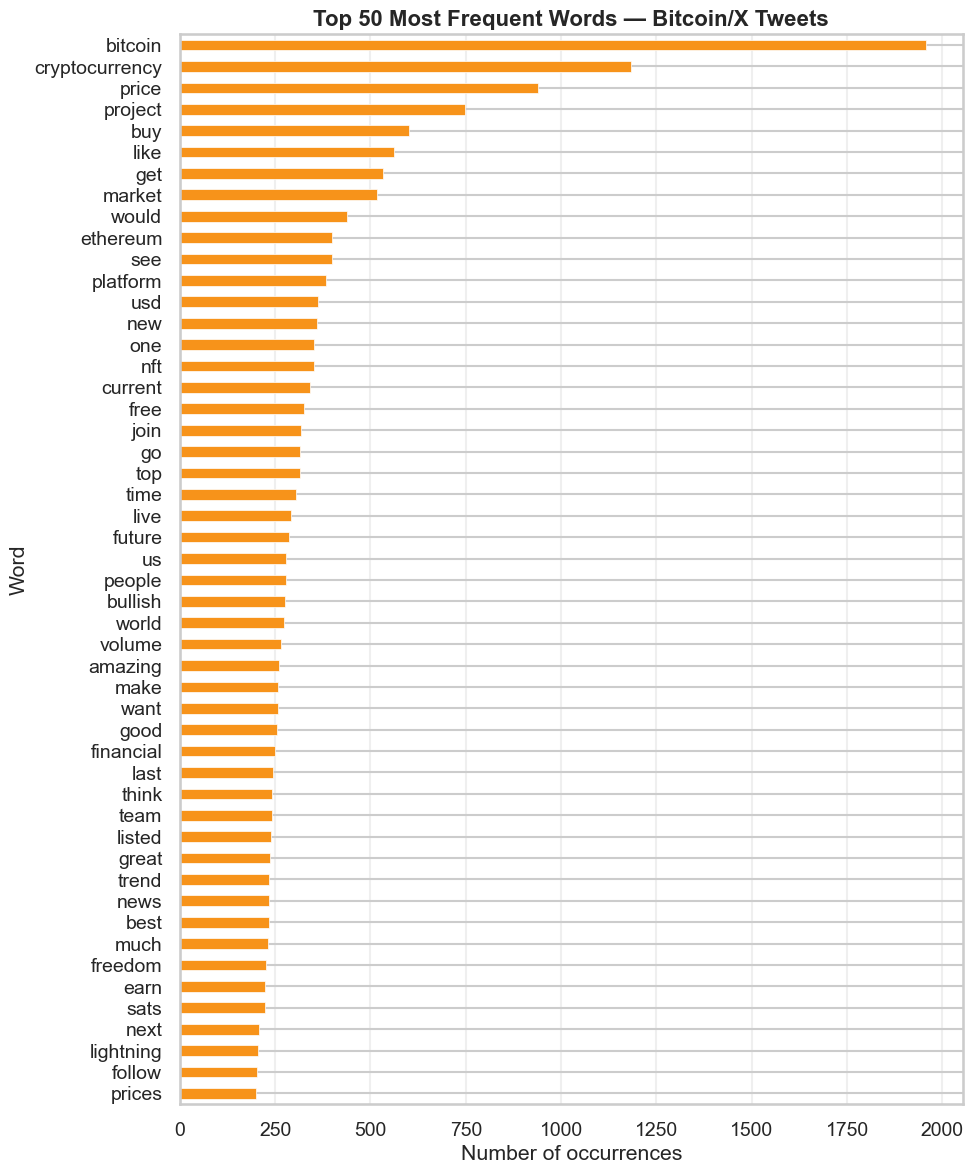

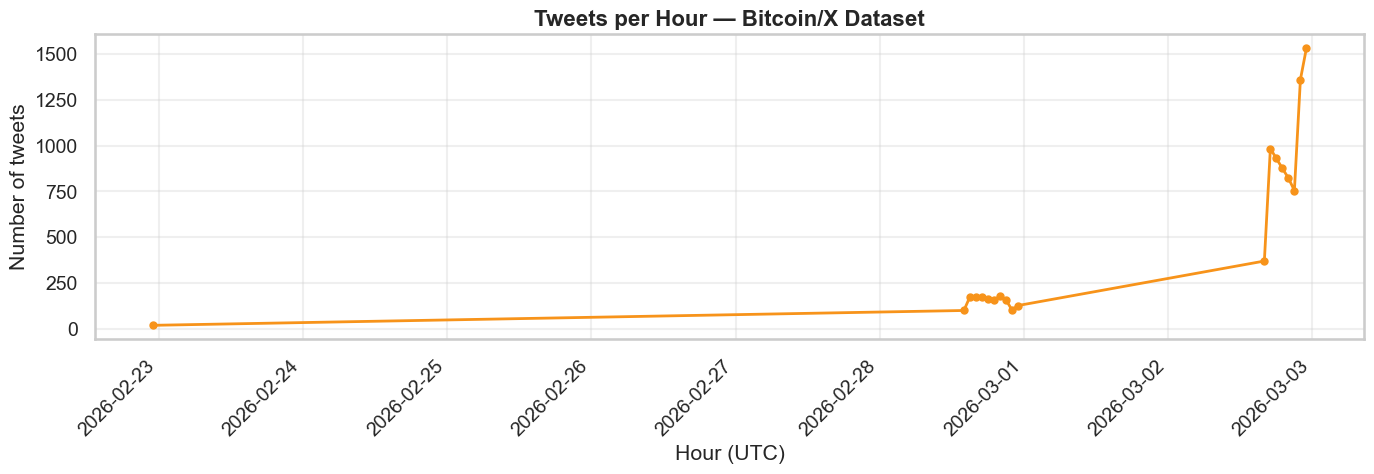

Top 5 words: bitcoin (1956), cryptocurrency (1184), price (940), project (749), buy (601)


In [ ]:
HASHTAG_RE = re.compile(r"#\w+")  # Extract hashtags
WORD_RE = re.compile(r"\b[a-z]{2,}\b")  # Match 2+ letter words

# Map common cryptocurrency terms to canonical forms (looser than NLP preprocessing)
WORD_CANONICAL = {
    "btc": "bitcoin", "bitcoins": "bitcoin", "xbt": "bitcoin",
    "eth": "ethereum", "ether": "ethereum", "etherum": "ethereum", "etherium": "ethereum",
    "crypto": "cryptocurrency", "cryptocurrencies": "cryptocurrency", "cryptos": "cryptocurrency",
    "nfts": "nft", "altcoins": "altcoin", "doge": "dogecoin", "matic": "polygon",
    "ada": "cardano", "sol": "solana", "xrp": "ripple", "ltc": "litecoin",
    "usdt": "tether", "avax": "avalanche", "link": "chainlink",
}

# Stop words for EDA
# Exclude common English stopwords + Bitcoin-specific noise (RT, amp, mentions)
EDA_STOP_WORDS = set(stopwords.words("english")) | {
    "rt", "amp", "via", "cc", "u", "ur", "dont", "im", "ive", "youre", "theyre",
    "were", "cant", "wont", "didnt", "doesnt", "isnt", "wasnt", "werent",
    "havent", "hasnt", "hadnt", "wouldnt", "couldnt", "shouldnt",
}


def tokenize_for_frequency(text: str) -> list[str]:
    # Extract words for frequency analysis: remove URLs/mentions/hashtags,
    # lowercase, and apply looser canonical mapping than NLP preprocessing.
    if not isinstance(text, str) or not text.strip():
        return []
    text = html.unescape(text).lower()
    text = URL_RE.sub(" ", text)
    text = MENTION_RE.sub(" ", text)
    text = HASHTAG_RE.sub(" ", text)
    text = re.sub(r"\$\s*", " ", text)  # Remove dollar signs
    text = re.sub(r"[^a-z\s]", " ", text)  # Keep only letters and spaces
    text = re.sub(r"\s+", " ", text).strip()
    tokens = []
    for word in WORD_RE.findall(text):
        word = WORD_CANONICAL.get(word, word)
        if word not in EDA_STOP_WORDS:
            tokens.append(word)
    return tokens


def top_words(dataframe: pd.DataFrame, n: int = TOP_N_WORDS) -> pd.Series:
    # Count word frequencies across all tweets, return top n.
    counter: Counter[str] = Counter()
    col = "text_raw" if "text_raw" in dataframe.columns else "text"
    for text in dataframe[col].fillna(""):
        counter.update(tokenize_for_frequency(text))
    return pd.Series(dict(counter.most_common(n)), name="count")


# Plot 1: Top words frequency
freq = top_words(df, n=TOP_N_WORDS).sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(10, 12))
freq.plot(kind="barh", ax=ax, color="#F7931A", edgecolor="white", linewidth=0.5)
ax.set_xlabel("Number of occurrences")
ax.set_ylabel("Word")
ax.set_title(f"Top {TOP_N_WORDS} Most Frequent Words — Bitcoin/X Tweets", fontsize=16, fontweight="bold")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
plt.show()

# Plot 2: Tweet volume over time
# Aggregate tweets by hour to show activity patterns
hourly = (
    df.assign(hour=df["date"].dt.floor("h"))
    .groupby("hour", sort=True)
    .size()
    .reset_index(name="tweet_count")
)
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(hourly["hour"], hourly["tweet_count"], color="#F7931A", linewidth=2, marker="o", markersize=5)
ax.set_xlabel("Hour (UTC)")
ax.set_ylabel("Number of tweets")
ax.set_title("Tweets per Hour — Bitcoin/X Dataset", fontsize=16, fontweight="bold")
ax.grid(alpha=0.3)
fig.autofmt_xdate(rotation=45, ha="right")
fig.tight_layout()
plt.show()

# Summary statistics
top5 = top_words(df, 5)
print(f"Top 5 words: {', '.join(f'{w} ({int(c)})' for w, c in top5.items())}")


## 3. Network analysis (Q1)


In [ ]:
# Network analysis: build mention and hashtag graphs, compute centrality

# Helper: Node sizing based on metric values
def node_sizes_from_values(values, *, min_size=NODE_SIZE_MIN, max_size=NODE_SIZE_MAX):
    # Scale values to node sizes [min_size, max_size].
    # Uses sqrt transformation then linear interpolation for visual clarity.
    arr = np.asarray(values, dtype=float)
    if len(arr) == 0:
        return []
    if arr.max() <= arr.min():
        mid = (min_size + max_size) / 2
        return [mid] * len(arr)
    scaled = np.sqrt(arr - arr.min() + 1.0)
    normed = (scaled - scaled.min()) / (scaled.max() - scaled.min())
    return (min_size + normed * (max_size - min_size)).tolist()


def norm_account(name) -> str:
    # Normalize account name: lowercase, remove non-alphanumeric.
    s = re.sub(r"[^a-z0-9_]", "", str(name).lower())
    return s if s else "unknown"


def parse_list_cell(value) -> list[str]:
    # Parse list column from CSV (may be string repr or actual list).
    if value is None or (isinstance(value, float) and pd.isna(value)):
        return []
    if isinstance(value, list):
        return [str(x) for x in value]
    text = str(value).strip()
    if not text or text == "[]":
        return []
    try:
        parsed = ast.literal_eval(text)
        return [str(x) for x in parsed]
    except (SyntaxError, ValueError):
        return []


def prepare_network_df(dataframe: pd.DataFrame) -> pd.DataFrame:
    # Prepare data for network analysis. Normalize author names and parse mention lists.
    out = dataframe.copy()
    out["author_id"] = out["user_name"].map(norm_account)
    out["mentions_list"] = out["mentions"].map(parse_list_cell)
    out["mention_ids"] = out["mentions_list"].map(
        lambda xs: [norm_account(m) for m in xs if norm_account(m) != "unknown"]
    )
    return out


def author_metadata(dataframe: pd.DataFrame) -> pd.DataFrame:
    # Extract author metadata: follower count (max across tweets),
    # verification status, and tweet count.
    meta = (
        dataframe.groupby("author_id", as_index=False)
        .agg(
            user_name=("user_name", "first"),
            followers=("user_followers", "max"),
            verified=("user_verified", lambda s: bool(s.any())),
            tweet_count=("author_id", "count"),
        )
    )
    return meta.set_index("author_id")


def build_mention_graph(dataframe: pd.DataFrame) -> nx.DiGraph:
    # Build directed mention graph:
    # - Nodes = unique accounts
    # - Edges = author -> mentioned account (weighted by count)
    g = nx.DiGraph()
    edge_weights: Counter[tuple[str, str]] = Counter()
    for author, mentions in zip(dataframe["author_id"], dataframe["mention_ids"]):
        if author == "unknown":
            continue
        for target in mentions:
            if not target or target == author:
                continue
            edge_weights[(author, target)] += 1
    for (u, v), w in edge_weights.items():
        if w >= MIN_EDGE_WEIGHT:
            g.add_edge(u, v, weight=w)
    return g


def build_hashtag_graph(dataframe: pd.DataFrame) -> nx.Graph:
    # Build undirected hashtag co-occurrence graph:
    # - Nodes = hashtags
    # - Edges = co-occurrence in same tweet (weight >= 2)
    g = nx.Graph()
    edge_weights: Counter[tuple[str, str]] = Counter()
    for tags in dataframe["hashtags"].map(parse_list_cell):
        tags = sorted(set(t.lower().strip() for t in tags if t))
        for a, b in combinations(tags, 2):
            edge_weights[tuple(sorted((a, b)))] += 1
    for (a, b), w in edge_weights.items():
        if w >= 2:
            g.add_edge(a, b, weight=w)
    return g


def top_nodes_subgraph(g, n: int, metric: str = "in_degree"):
    # Extract subgraph of top n nodes by specified metric.
    if g.number_of_nodes() == 0:
        return g.copy()
    if isinstance(g, nx.DiGraph):
        if metric == "in_degree":
            scores = dict(g.in_degree(weight="weight"))
        elif metric == "weighted_degree":
            scores = {
                node: g.in_degree(node, weight="weight") + g.out_degree(node, weight="weight")
                for node in g.nodes
            }
        else:
            scores = dict(g.degree(weight="weight"))
    else:
        scores = dict(g.degree(weight="weight"))
    top = sorted(scores, key=scores.get, reverse=True)[:n]
    return g.subgraph(top).copy()


def mention_ego_subgraph(g: nx.DiGraph, top_n: int = 25, max_nodes: int = 90) -> nx.DiGraph:
    # Extract ego network around top mentioned accounts. Find top_n by in-degree, include predecessors/successors.
    ranked = sorted(g.in_degree(weight="weight"), key=lambda x: x[1], reverse=True)
    seeds = [n for n, d in ranked[:top_n] if d > 0]
    nodes: set[str] = set(seeds)
    for seed in seeds:
        nodes.update(g.predecessors(seed))
        nodes.update(g.successors(seed))
    if len(nodes) > max_nodes:
        extra = sorted(
            nodes - set(seeds),
            key=lambda n: g.in_degree(n, weight="weight") + g.out_degree(n, weight="weight"),
            reverse=True,
        )
        nodes = set(seeds) | set(extra[: max_nodes - len(seeds)])
    return g.subgraph(nodes).copy()


def centrality_tables(g: nx.DiGraph, meta: pd.DataFrame) -> pd.DataFrame:
    # Compute network centrality measures for all nodes. In/out degree, betweenness, PageRank; merge with author metadata.
    in_deg = dict(g.in_degree(weight="weight"))
    out_deg = dict(g.out_degree(weight="weight"))
    between = nx.betweenness_centrality(g, weight="weight", normalized=True)
    try:
        pagerank = nx.pagerank(g, weight="weight")
    except nx.PowerIterationFailedConvergence:
        pagerank = {n: 0.0 for n in g.nodes}
    rows = []
    for node in g.nodes:
        m = meta.loc[node] if node in meta.index else None
        rows.append({
            "account_id": node,
            "display_name": m["user_name"] if m is not None else node,
            "followers": int(m["followers"]) if m is not None else np.nan,
            "verified": bool(m["verified"]) if m is not None else False,
            "tweet_count": int(m["tweet_count"]) if m is not None else 0,
            "in_degree_weighted": in_deg.get(node, 0),
            "out_degree_weighted": out_deg.get(node, 0),
            "betweenness": between.get(node, 0.0),
            "pagerank": pagerank.get(node, 0.0),
        })
    return pd.DataFrame(rows).sort_values("in_degree_weighted", ascending=False)


def hashtag_centrality_table(g: nx.Graph) -> pd.DataFrame:
    # Compute centrality measures for hashtags. Weighted degree and betweenness.
    deg = dict(g.degree(weight="weight"))
    between = nx.betweenness_centrality(g, weight="weight", normalized=True)
    rows = [
        {"hashtag": n, "weighted_degree": deg[n], "betweenness": between.get(n, 0.0)}
        for n in g.nodes
    ]
    return pd.DataFrame(rows).sort_values("weighted_degree", ascending=False)


def draw_network_communities(g: nx.Graph, *, title: str) -> None:
    # Visualize network with Louvain community detection.
    # Each community gets a distinct color.
    if g.number_of_nodes() < 3:
        return
    communities = nx.community.louvain_communities(g, weight="weight", seed=42)
    node_color = {}
    cmap = plt.colormaps["tab10"]
    for i, comm in enumerate(communities):
        for node in comm:
            node_color[node] = i
    fig, ax = plt.subplots(figsize=NETWORK_FIGSIZE)
    pos = nx.spring_layout(g, seed=42, k=1.8 / max(np.sqrt(g.number_of_nodes()), 1))
    degrees = [g.degree(n, weight="weight") for n in g.nodes]
    sizes = node_sizes_from_values(degrees)
    colors = [node_color.get(n, 0) for n in g.nodes]
    max_w = max((d.get("weight", 1) for _, _, d in g.edges(data=True)), default=1)
    widths = [0.6 + 2.5 * d.get("weight", 1) / max_w for _, _, d in g.edges(data=True)]
    nx.draw_networkx_edges(g, pos, ax=ax, width=widths, alpha=0.35, edge_color="#888888")
    nx.draw_networkx_nodes(
        g, pos, node_size=sizes, node_color=colors, cmap=cmap,
        edgecolors="#333333", linewidths=0.6, ax=ax,
    )
    labels = {n: str(n)[:16] for n in g.nodes}
    nx.draw_networkx_labels(g, pos, labels=labels, font_size=FONT_NODE_LABEL, font_weight="bold", ax=ax)
    ax.set_title(title, fontsize=FONT_NETWORK_TITLE, fontweight="bold", pad=14)
    ax.axis("off")
    fig.tight_layout()
    plt.show()


def draw_network(
    g,
    *,
    title: str,
    label_map: dict[str, str] | None = None,
    size_metric: str = "degree",
    use_account_id_labels: bool = False,
) -> None:
    if g.number_of_nodes() == 0:
        return
    fig, ax = plt.subplots(figsize=NETWORK_FIGSIZE)
    pos = nx.spring_layout(g, seed=42, k=1.8 / max(np.sqrt(g.number_of_nodes()), 1))
    if isinstance(g, nx.DiGraph):
        colors = [g.in_degree(n, weight="weight") for n in g.nodes] if size_metric == "in_degree" else [g.degree(n, weight="weight") for n in g.nodes]
        max_w = max((d.get("weight", 1) for _, _, d in g.edges(data=True)), default=1)
        widths = [0.6 + 2.5 * d.get("weight", 1) / max_w for _, _, d in g.edges(data=True)]
        nx.draw_networkx_edges(
            g, pos, ax=ax, width=widths, alpha=0.35, edge_color="#666666",
            arrows=True, arrowsize=16, connectionstyle="arc3,rad=0.08",
        )
    else:
        colors = [g.degree(n, weight="weight") for n in g.nodes]
        max_w = max((d.get("weight", 1) for _, _, d in g.edges(data=True)), default=1)
        widths = [0.6 + 2.5 * d.get("weight", 1) / max_w for _, _, d in g.edges(data=True)]
        nx.draw_networkx_edges(g, pos, ax=ax, width=widths, alpha=0.4, edge_color="#888888")
    sizes = node_sizes_from_values(colors)
    nodes = list(g.nodes)
    norm = Normalize(vmin=min(colors) if colors else 0, vmax=max(colors) if colors else 1)
    cmap = plt.colormaps["YlOrBr"]
    nx.draw_networkx_nodes(
        g, pos, nodelist=nodes, node_size=sizes,
        node_color=colors, cmap=cmap, vmin=norm.vmin, vmax=norm.vmax,
        edgecolors="#333333", linewidths=0.6, ax=ax,
    )
    labels = {}
    for n in nodes:
        if use_account_id_labels:
            labels[n] = str(n)[:18]
        else:
            raw = label_map.get(n, n) if label_map else n
            labels[n] = str(raw)[:18]
    nx.draw_networkx_labels(g, pos, labels=labels, font_size=FONT_NODE_LABEL, font_weight="bold", ax=ax)
    sm = ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, shrink=0.7, pad=0.02)
    cbar_label = "Weighted degree" if not isinstance(g, nx.DiGraph) else "Weighted in-degree"
    cbar.set_label(cbar_label, fontsize=FONT_COLORBAR_LABEL)
    cbar.ax.tick_params(labelsize=FONT_COLORBAR_TICK)
    ax.set_title(title, fontsize=FONT_NETWORK_TITLE, fontweight="bold", pad=14)
    ax.axis("off")
    fig.tight_layout()
    plt.show()


def bar_top_metric(table: pd.DataFrame, column: str, label: str, *, name_col: str = "display_name", ylabel: str = "Account") -> None:
    # Bar chart showing top 15 accounts/hashtags by given metric.
    top = table.nlargest(TOP_BAR, column)
    fig, ax = plt.subplots(figsize=(10, 6))
    if "verified" in top.columns:
        colors = np.where(top["verified"], "#1DA1F2", "#F7931A")
        bar_labels = top["account_id"] if "account_id" in top.columns else top[name_col]
    else:
        colors = "#F7931A"
        bar_labels = top[name_col]
    ax.barh(bar_labels.astype(str).str[:28], top[column], color=colors)
    ax.set_xlabel(label, fontsize=FONT_AXIS)
    ax.set_ylabel(ylabel, fontsize=FONT_AXIS)
    ax.set_title(f"Top {TOP_BAR} by {label}", fontsize=FONT_TITLE, fontweight="bold")
    ax.tick_params(axis="both", labelsize=FONT_TICK)
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.3)
    if "verified" in top.columns:
        from matplotlib.patches import Patch
        ax.legend(
            handles=[
                Patch(color="#1DA1F2", label="Verified (any tweet)"),
                Patch(color="#F7931A", label="Not verified"),
            ],
            loc="lower right", fontsize=FONT_LEGEND,
        )
    fig.tight_layout()
    plt.show()


def plot_in_vs_out(table: pd.DataFrame) -> None:
    # Scatter: out-degree vs in-degree, colored by verification status.
    sub = table[(table["in_degree_weighted"] > 0) | (table["out_degree_weighted"] > 0)]
    fig, ax = plt.subplots(figsize=(8, 7))
    ax.scatter(
        sub["out_degree_weighted"], sub["in_degree_weighted"],
        c=np.where(sub["verified"], "#1DA1F2", "#F7931A"),
        alpha=0.65, s=30 + 3 * np.sqrt(sub["tweet_count"].clip(1)),
        edgecolors="white", linewidth=0.3,
    )
    ax.set_xlabel("Weighted out-degree (mentions made)", fontsize=FONT_AXIS)
    ax.set_ylabel("Weighted in-degree (mentions received)", fontsize=FONT_AXIS)
    ax.set_title("Mention activity: received vs initiated", fontsize=FONT_TITLE, fontweight="bold")
    ax.tick_params(labelsize=FONT_TICK)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()


def plot_centrality_vs_followers(table: pd.DataFrame) -> None:
    # Scatter: log(followers) vs in-degree (network prominence vs follower count).
    sub = table[table["followers"].notna() & (table["in_degree_weighted"] > 0)].copy()
    sub["log_followers"] = np.log1p(sub["followers"])
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.scatter(
        sub["log_followers"], sub["in_degree_weighted"],
        c=np.where(sub["verified"], "#1DA1F2", "#F7931A"),
        alpha=0.65, s=35, edgecolors="white", linewidth=0.3,
    )
    ax.set_xlabel("log(1 + follower count)", fontsize=FONT_AXIS)
    ax.set_ylabel("Weighted in-degree (mentions received)", fontsize=FONT_AXIS)
    ax.set_title("Network prominence vs follower count", fontsize=FONT_TITLE, fontweight="bold")
    ax.tick_params(labelsize=FONT_TICK)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()


def plot_degree_distribution(g: nx.DiGraph) -> None:
    # Histogram: degree distribution for mention network.
    # Compares weighted in-degree and out-degree distributions.
    in_vals = [d for _, d in g.in_degree(weight="weight") if d > 0]
    out_vals = [d for _, d in g.out_degree(weight="weight") if d > 0]
    fig, ax = plt.subplots(figsize=(9, 5))
    if in_vals:
        sns.histplot(in_vals, bins=30, color="#F7931A", alpha=0.55, label="In-degree", ax=ax)
    if out_vals:
        sns.histplot(out_vals, bins=30, color="#4a4e69", alpha=0.45, label="Out-degree", ax=ax)
    ax.set_xlabel("Weighted degree", fontsize=FONT_AXIS)
    ax.set_ylabel("Number of accounts", fontsize=FONT_AXIS)
    ax.set_title("Distribution of mention degrees in the interaction network", fontsize=FONT_TITLE, fontweight="bold")
    ax.tick_params(labelsize=FONT_TICK)
    ax.legend(fontsize=FONT_LEGEND)
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    plt.show()


# Build networks and compute metrics
net_df = prepare_network_df(df)
meta = author_metadata(net_df)
mention_g = build_mention_graph(net_df)
hashtag_g = build_hashtag_graph(net_df)
centrality = centrality_tables(mention_g, meta)
ht_table = hashtag_centrality_table(hashtag_g)
label_map = meta["user_name"].to_dict()

print(f"Mention network: {mention_g.number_of_nodes():,} nodes, {mention_g.number_of_edges():,} edges")
print(f"Hashtag network: {hashtag_g.number_of_nodes():,} nodes, {hashtag_g.number_of_edges():,} edges")
if not centrality.empty:
    top = centrality.iloc[0]
    print(f"Top by in-degree: {top['display_name']} (in={int(top['in_degree_weighted'])})")


Mention network: 4,948 nodes, 5,598 edges
Hashtag network: 1,624 nodes, 12,658 edges
Top by in-degree: bluesparrowc (in=290)


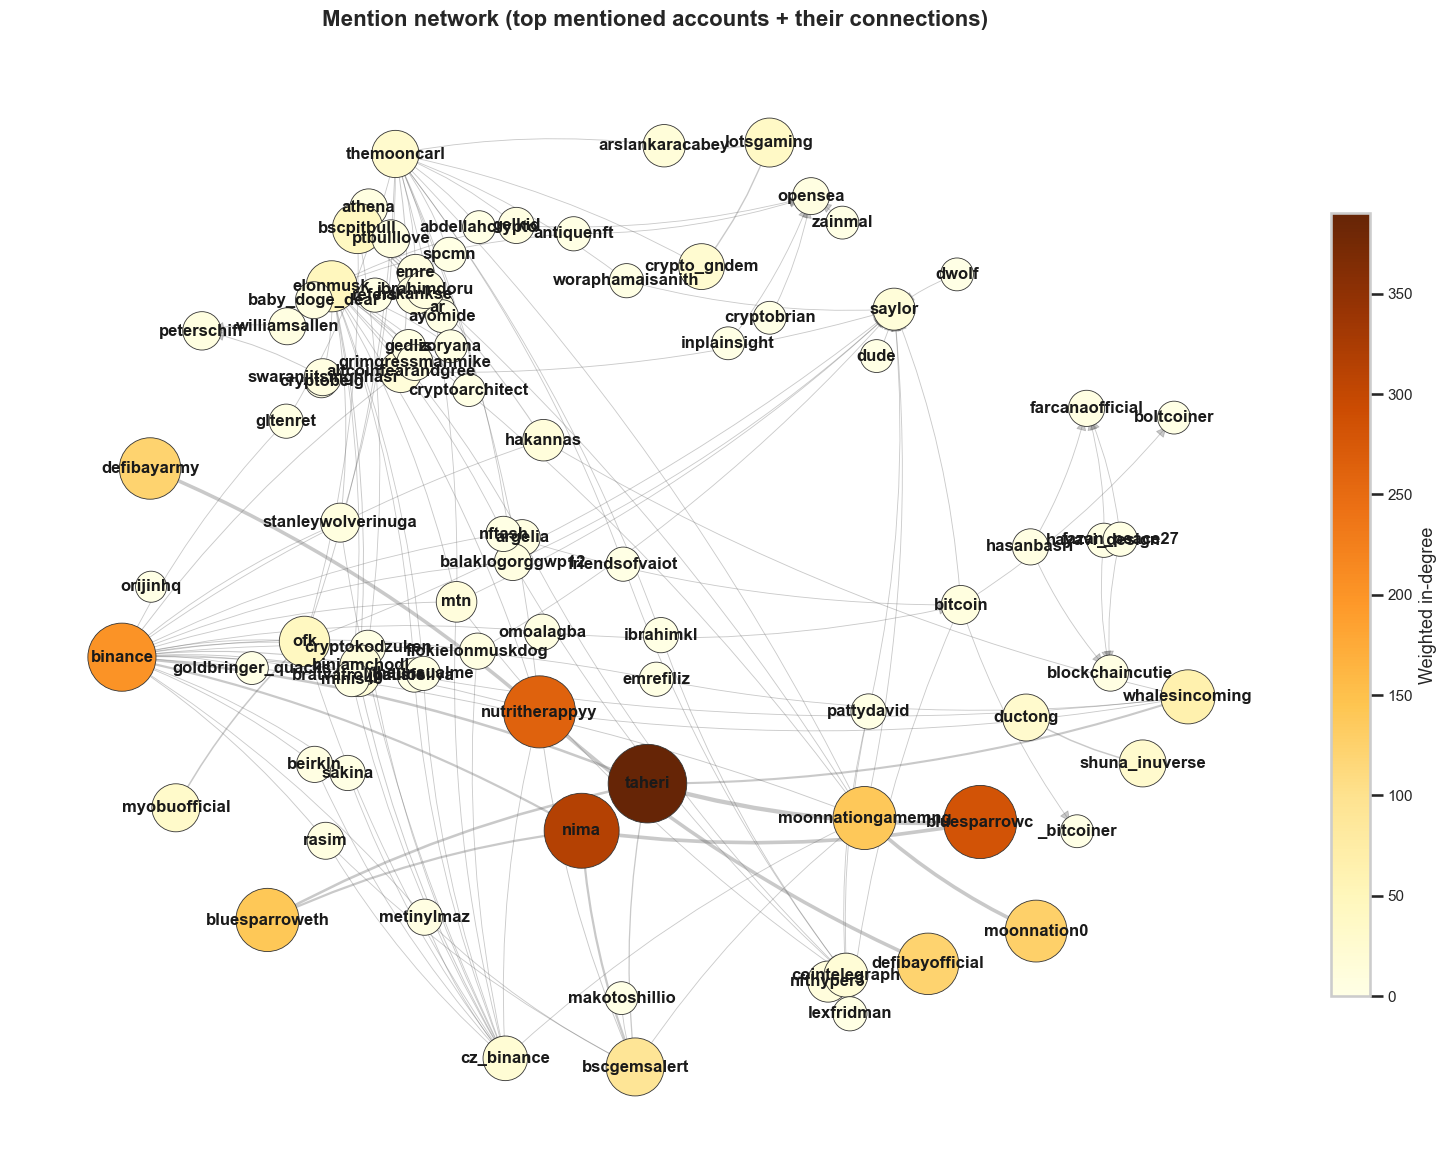

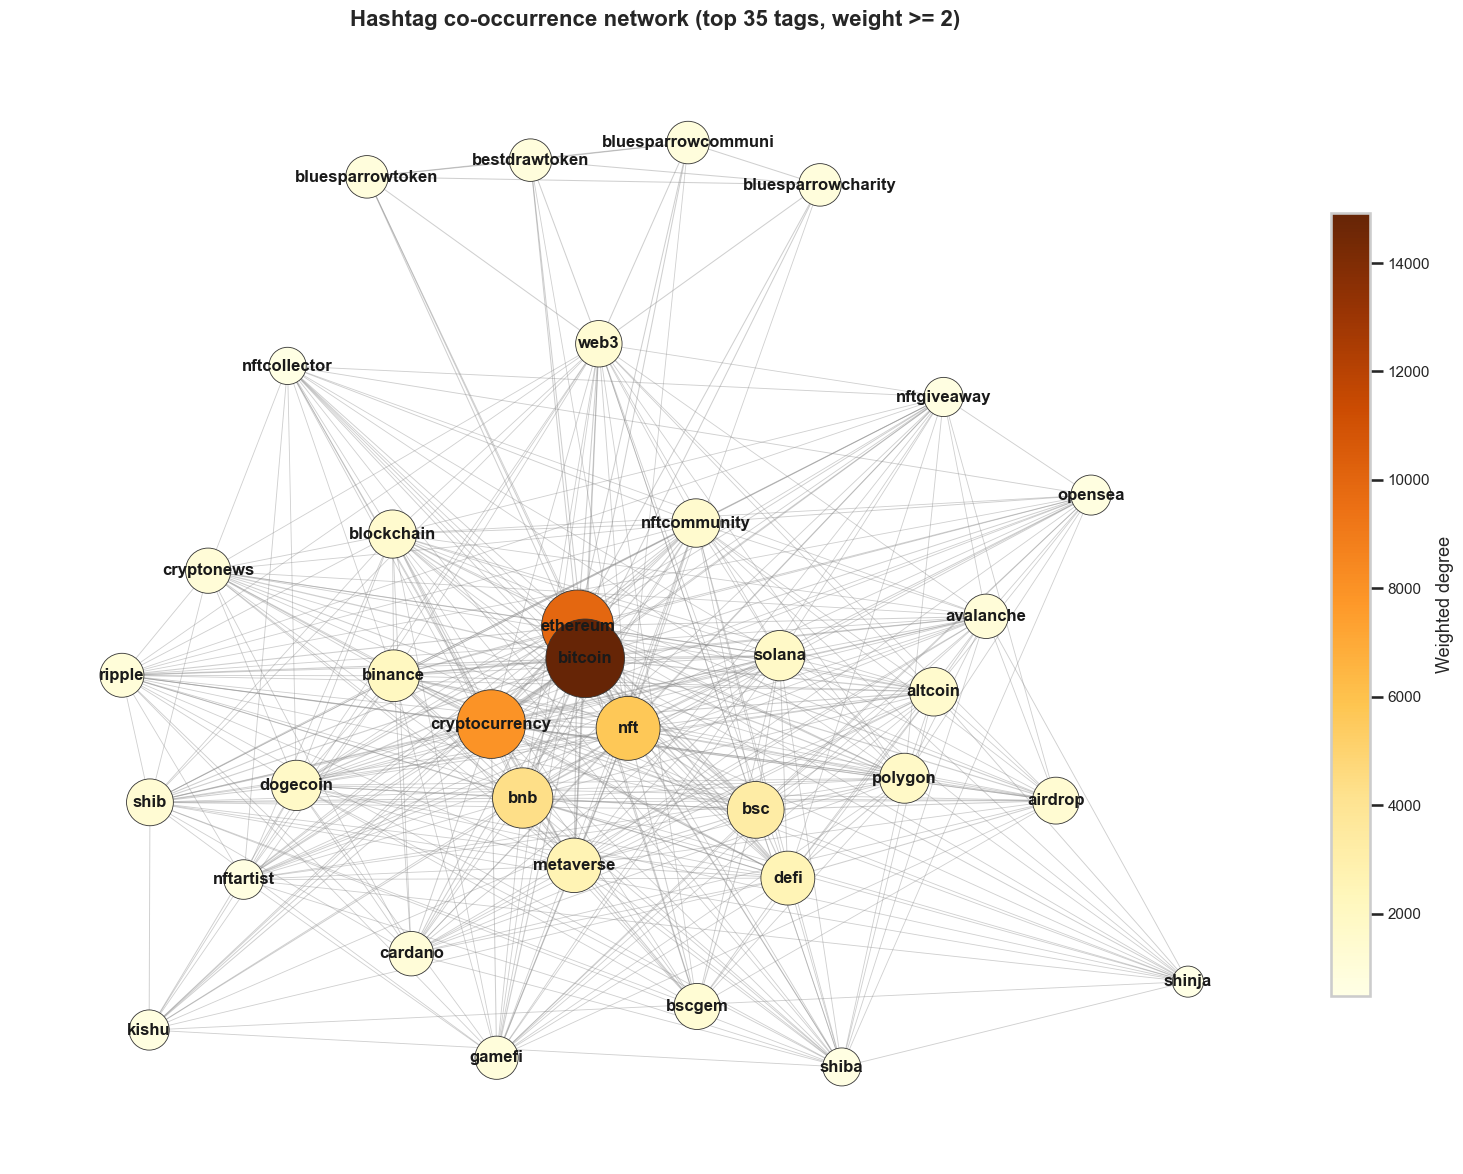

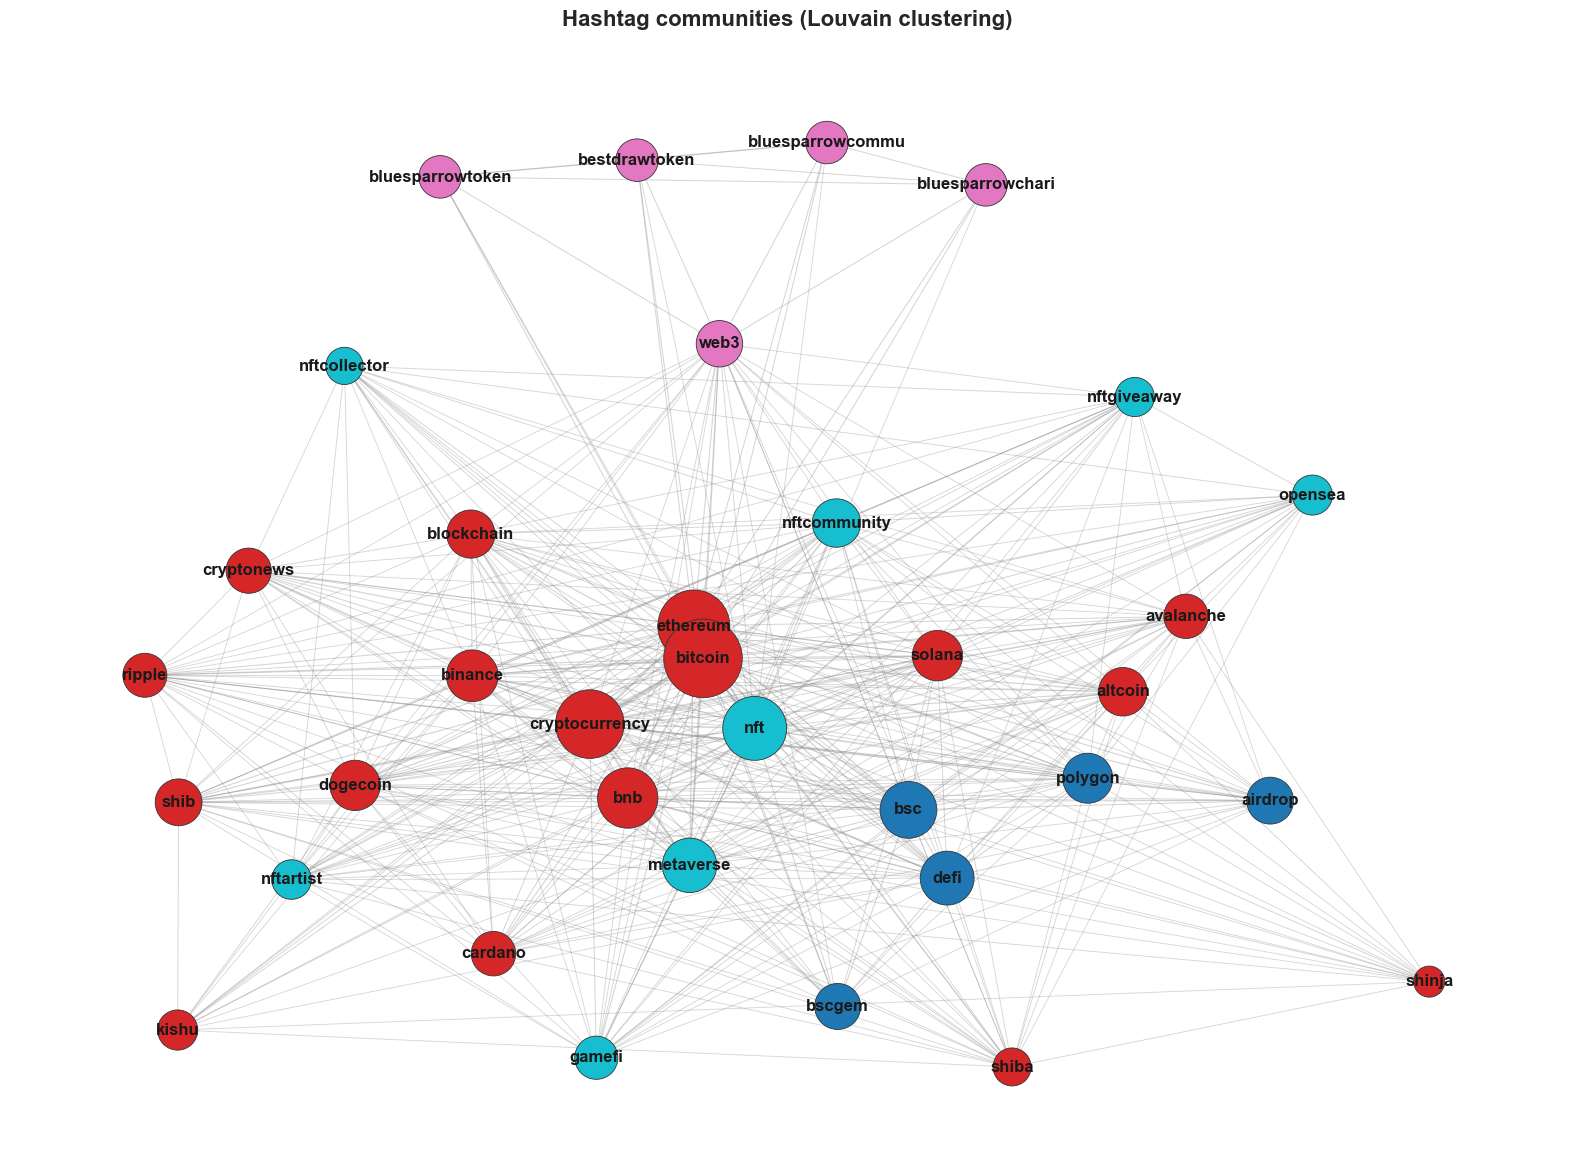

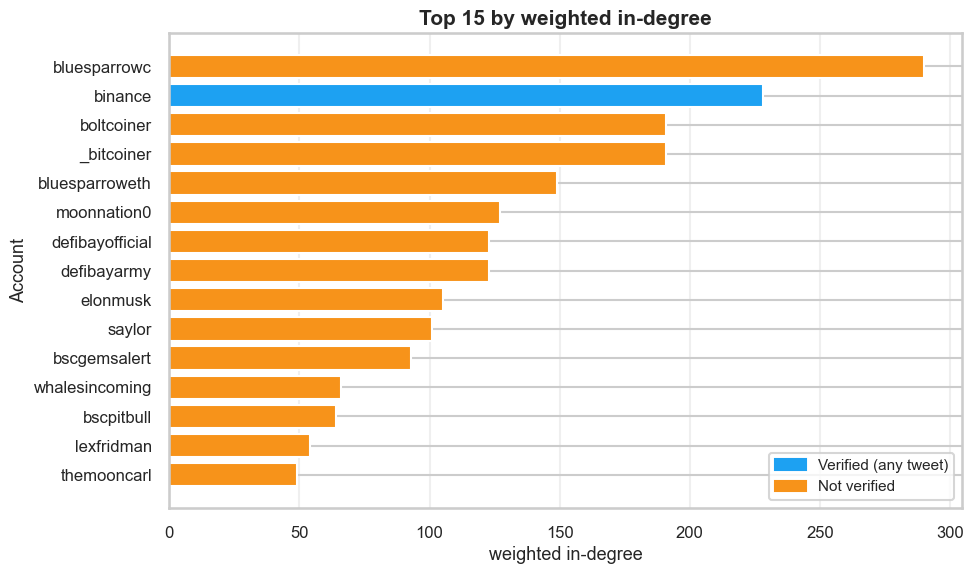

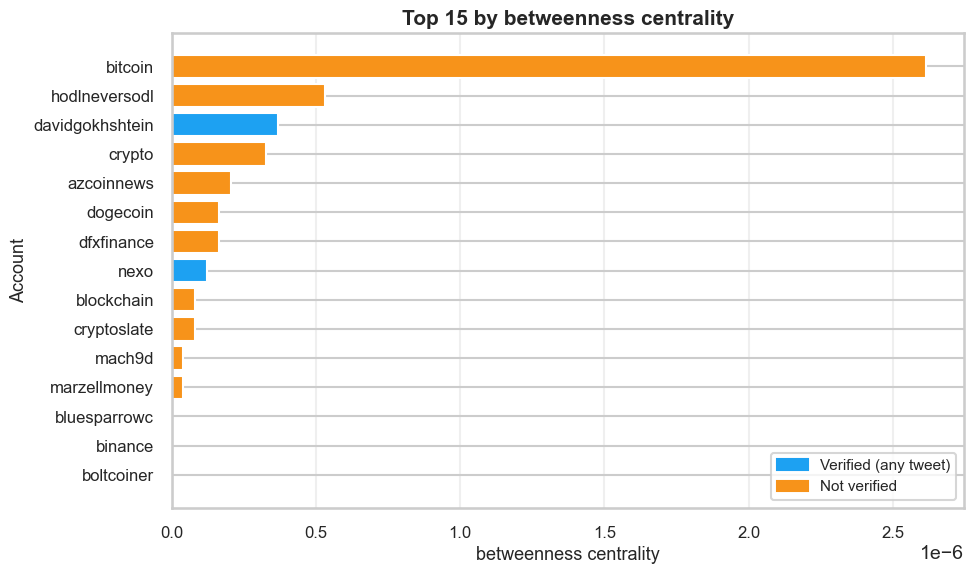

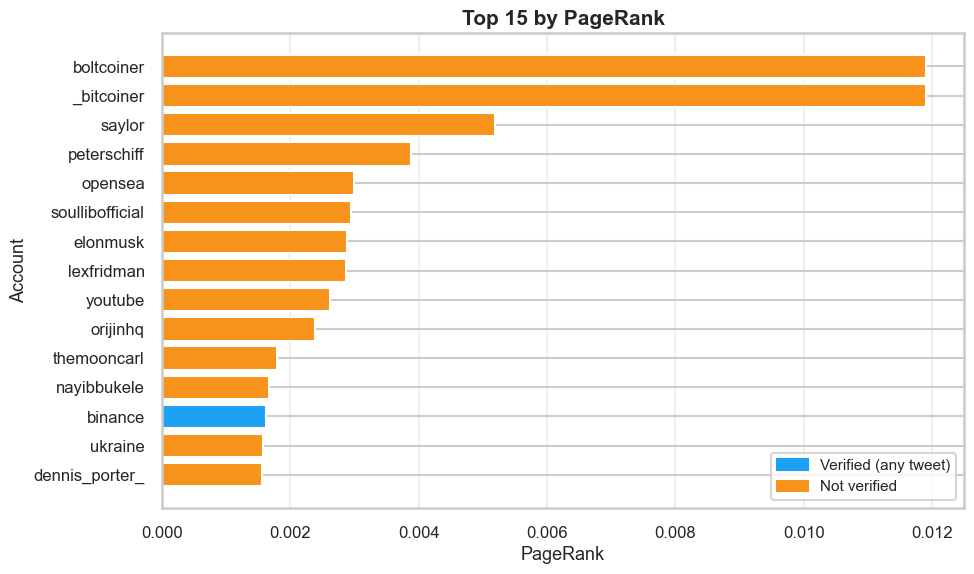

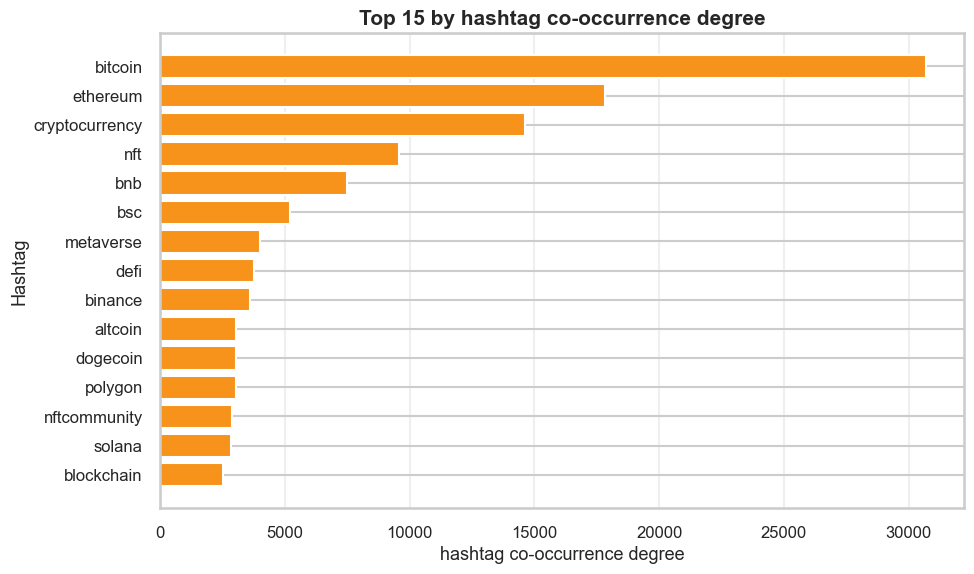

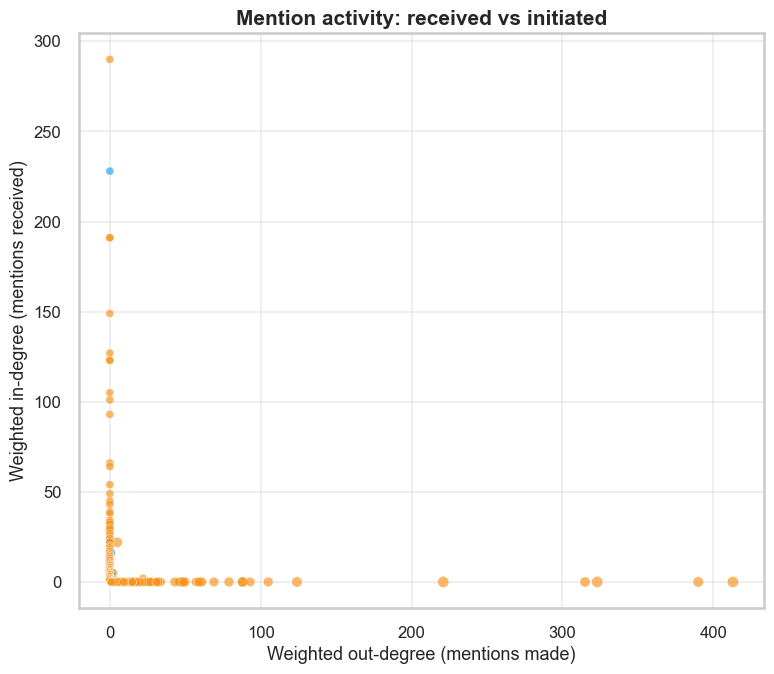

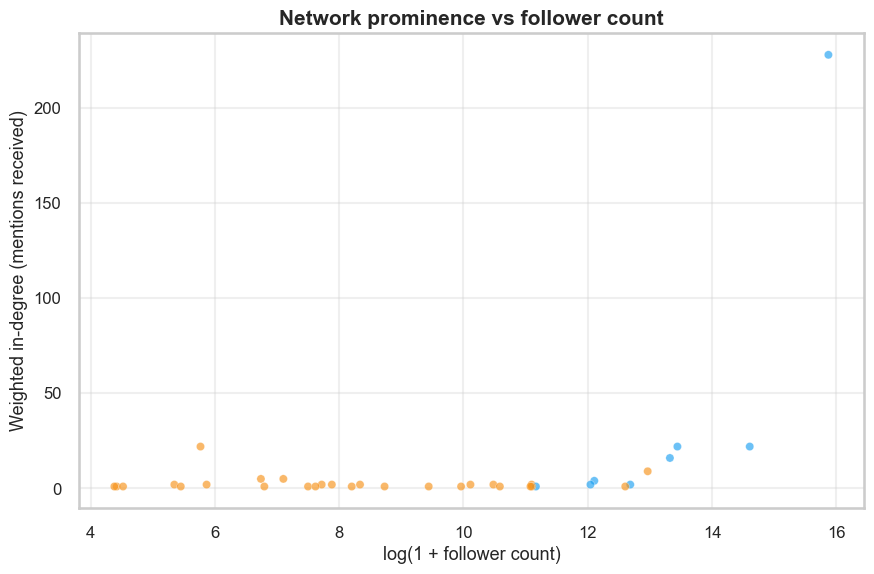

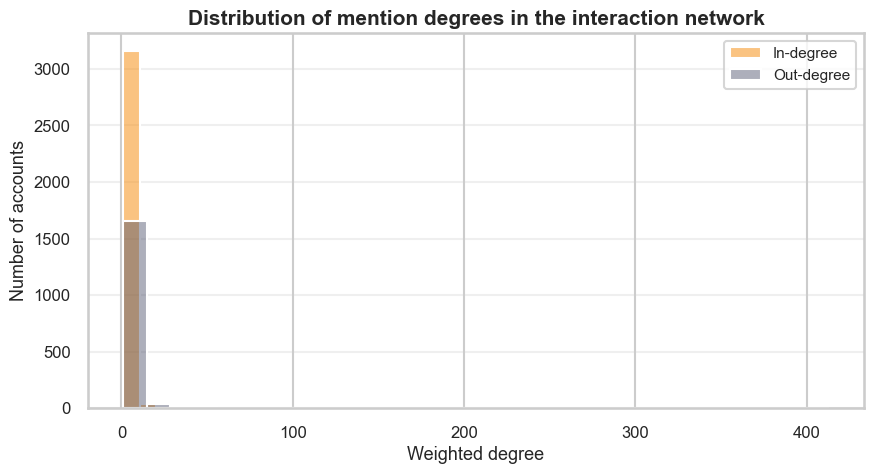

In [ ]:
# Generate network and centrality visualizations (Q1)

# Mention network: ego graph
# Extract ego network around top 25 mentioned accounts (Q1)
mention_sub = mention_ego_subgraph(mention_g, top_n=25, max_nodes=90)
draw_network(
    mention_sub,
    title="Mention network (top mentioned accounts + their connections)",
    label_map=label_map,
    use_account_id_labels=True,
)

# Hashtag network visualizations
# Top hashtags by co-occurrence frequency
hashtag_sub = top_nodes_subgraph(hashtag_g, TOP_HASHTAGS)
draw_network(
    hashtag_sub,
    title=f"Hashtag co-occurrence network (top {TOP_HASHTAGS} tags, weight >= 2)",
    size_metric="degree",
)
# Detect and visualize hashtag communities using Louvain clustering
draw_network_communities(hashtag_sub, title="Hashtag communities (Louvain clustering)")

# Centrality metric bar charts
# Compare different centrality measures for top accounts
bar_top_metric(centrality, "in_degree_weighted", "weighted in-degree")
bar_top_metric(centrality, "betweenness", "betweenness centrality")
bar_top_metric(centrality, "pagerank", "PageRank")
bar_top_metric(ht_table, "weighted_degree", "hashtag co-occurrence degree", name_col="hashtag", ylabel="Hashtag")

# Account activity and follower analysis
# Compare who mentions whom vs account follower counts
plot_in_vs_out(centrality)
plot_centrality_vs_followers(centrality)
plot_degree_distribution(mention_g)


## 4. Sentiment analysis (Q2) — VADER on text_raw


In [ ]:
# Sentiment analysis: VADER sentiment scoring on raw tweet text

def label_from_compound(compound: float) -> str:
    # Convert VADER compound score to sentiment label. compound >= 0.05 -> positive, <= -0.05 -> negative, else neutral.
    if compound >= POSITIVE_THRESHOLD:
        return "positive"
    if compound <= NEGATIVE_THRESHOLD:
        return "negative"
    return "neutral"


def score_text(text: str) -> dict:
    # Analyze tweet sentiment using VADER.
    # Returns neg/neu/pos scores, compound, and label dict.
    scores = analyzer.polarity_scores(text or "")
    compound = scores["compound"]
    return {
        "sentiment_neg": round(scores["neg"], 4),
        "sentiment_neu": round(scores["neu"], 4),
        "sentiment_pos": round(scores["pos"], 4),
        "sentiment_compound": round(compound, 4),
        "sentiment_label": label_from_compound(compound),
    }


# Apply VADER to all tweets
sentiment_rows = [score_text(t) for t in df["text_raw"].fillna("")]
sent_df = pd.DataFrame(sentiment_rows)
df = pd.concat([df.reset_index(drop=True), sent_df], axis=1)

# Print sentiment distribution
label_counts = df["sentiment_label"].value_counts()
n = len(df)
print("Sentiment labels (VADER compound score):")
for lab in ("positive", "neutral", "negative"):
    c = int(label_counts.get(lab, 0))
    print(f"  {lab:8} {c:5,}  ({100 * c / n:.1f}%)")


Sentiment labels (VADER compound score):
  positive 4,724  (51.6%)
  neutral  3,067  (33.5%)
  negative 1,362  (14.9%)


## 5. Sentiment-coloured network (Q3)


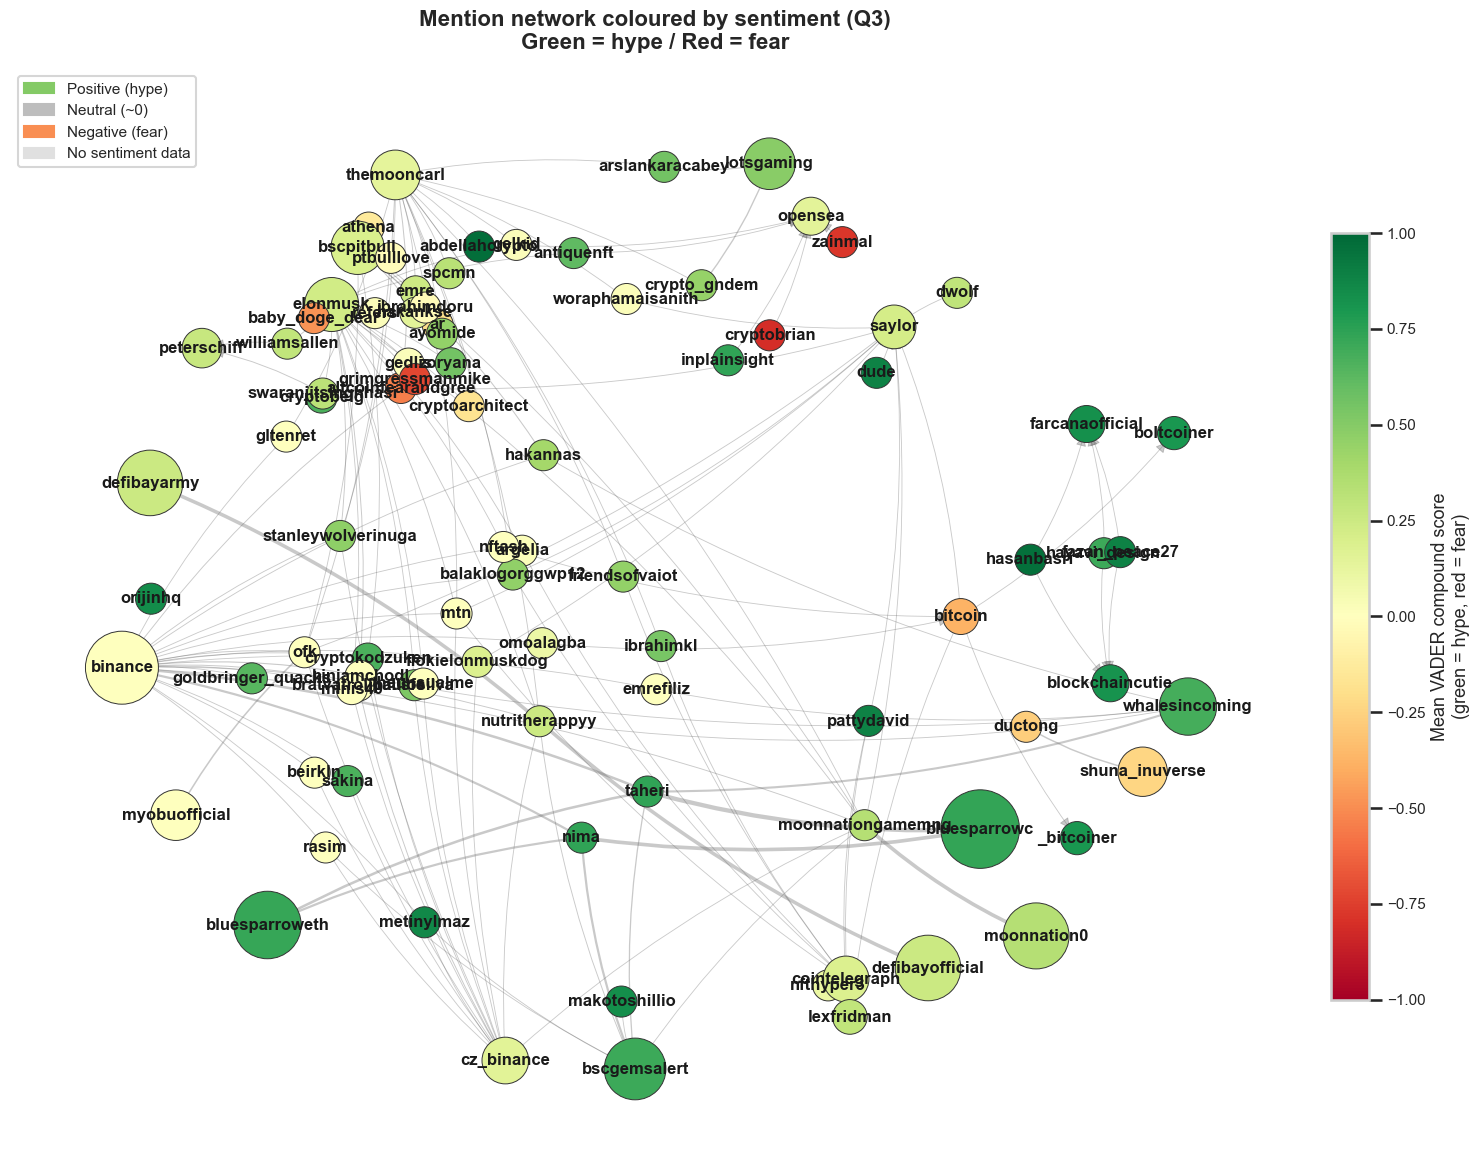

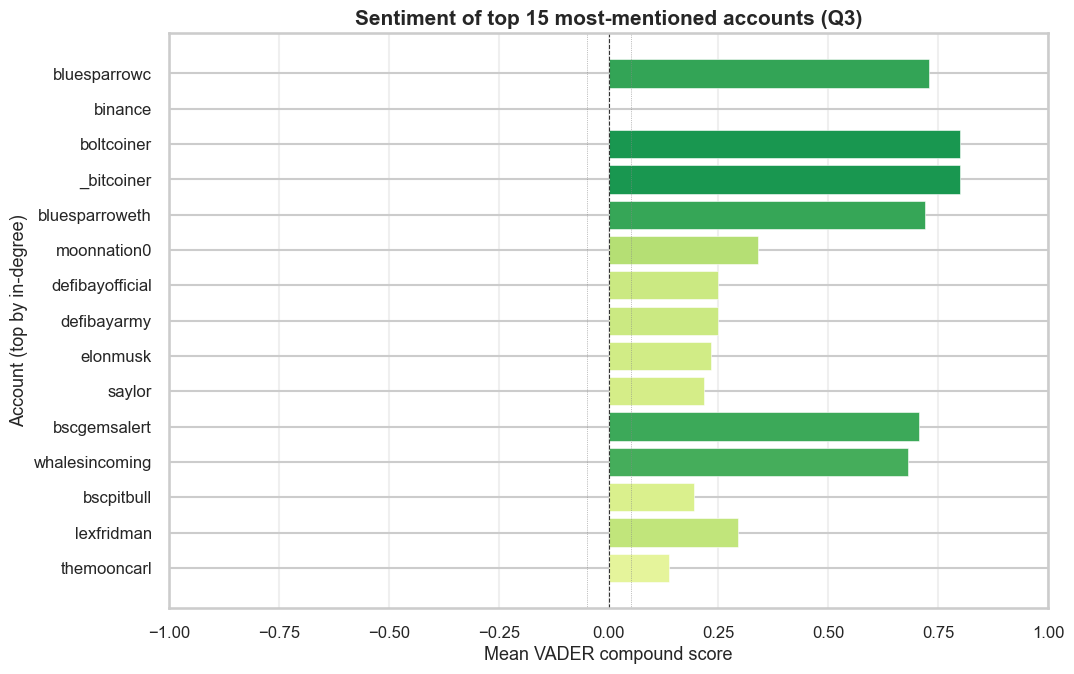

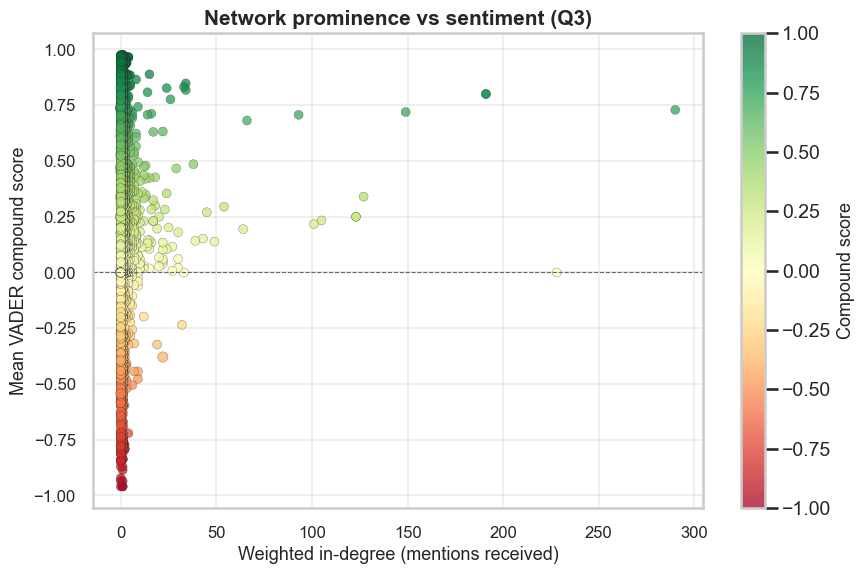

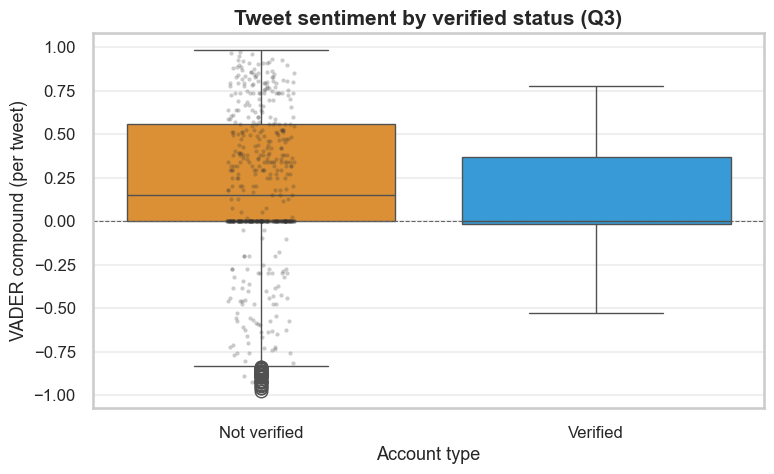

Top mentioned accounts (in-degree) and sentiment:
  bluesparrowc: in-degree=290, compound=0.729 (mentioned)
  binance: in-degree=228, compound=0.000 (author)
  boltcoiner: in-degree=191, compound=0.800 (mentioned)
  _bitcoiner: in-degree=191, compound=0.800 (mentioned)
  bluesparroweth: in-degree=149, compound=0.719 (mentioned)


In [ ]:
# Sentiment-colored network: integrate sentiment into mention graphs

def account_sentiment_profiles(dataframe: pd.DataFrame) -> pd.DataFrame:
    # Build sentiment profiles for accounts. author_sentiment from own tweets; mentioned_sentiment from tweets mentioning them.
    work = prepare_network_df(dataframe)
    author = (
        work.groupby("author_id")
        .agg(
            author_sentiment=("sentiment_compound", "mean"),
            author_tweets=("sentiment_compound", "count"),
            author_pos_share=("sentiment_label", lambda s: (s == "positive").mean()),
            author_neg_share=("sentiment_label", lambda s: (s == "negative").mean()),
        )
    )
    # Collect sentiment of tweets that mention each account
    mention_rows = []
    for compound, mids in zip(work["sentiment_compound"], work["mention_ids"]):
        for mid in mids:
            mention_rows.append({"account_id": mid, "compound": compound})
    if mention_rows:
        mentioned = (
            pd.DataFrame(mention_rows)
            .groupby("account_id")
            .agg(mentioned_sentiment=("compound", "mean"), mentioned_tweet_count=("compound", "count"))
        )
    else:
        mentioned = pd.DataFrame(columns=["mentioned_sentiment", "mentioned_tweet_count"]).set_index(
            pd.Index([], name="account_id")
        )
    profiles = author.join(mentioned, how="outer")
    # Use author sentiment if available, else use mentioned sentiment
    profiles["node_sentiment"] = np.where(
        profiles["author_tweets"].fillna(0) > 0,
        profiles["author_sentiment"],
        profiles["mentioned_sentiment"],
    )
    profiles["sentiment_source"] = np.where(
        profiles["author_tweets"].fillna(0) > 0,
        "author",
        np.where(profiles["mentioned_tweet_count"].fillna(0) > 0, "mentioned", "none"),
    )
    return profiles


def draw_mention_network_sentiment(g: nx.DiGraph, profiles: pd.DataFrame, *, title: str) -> None:
    # Visualize mention network with nodes colored by sentiment. RdYlGn colormap: green = hype, red = fear.
    if g.number_of_nodes() == 0:
        return
    fig, ax = plt.subplots(figsize=NETWORK_FIGSIZE)
    pos = nx.spring_layout(g, seed=42, k=1.8 / max(np.sqrt(g.number_of_nodes()), 1))
    in_deg = [g.in_degree(n, weight="weight") for n in g.nodes]
    sizes = node_sizes_from_values(in_deg)
    max_w = max((d.get("weight", 1) for _, _, d in g.edges(data=True)), default=1)
    widths = [0.6 + 2.5 * d.get("weight", 1) / max_w for _, _, d in g.edges(data=True)]
    # Color nodes by sentiment using diverging colormap (red-yellow-green)
    cmap = plt.colormaps["RdYlGn"]
    norm = TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1)
    face_colors = []
    for node in g.nodes:
        if node in profiles.index and pd.notna(profiles.loc[node, "node_sentiment"]):
            face_colors.append(cmap(norm(float(profiles.loc[node, "node_sentiment"]))))
        else:
            face_colors.append(MISSING_GRAY)
    nx.draw_networkx_edges(
        g, pos, ax=ax, width=widths, alpha=0.35, edge_color="#666666",
        arrows=True, arrowsize=16, connectionstyle="arc3,rad=0.08",
    )
    nx.draw_networkx_nodes(
        g, pos, node_size=sizes, node_color=face_colors,
        edgecolors="#333333", linewidths=0.7, ax=ax,
    )
    labels = {n: str(n)[:18] for n in g.nodes}
    nx.draw_networkx_labels(g, pos, labels=labels, font_size=FONT_NODE_LABEL, font_weight="bold", ax=ax)
    # Add colorbar showing sentiment scale
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, shrink=0.7, pad=0.02)
    cbar.set_label("Mean VADER compound score\n(green = hype, red = fear)", fontsize=FONT_COLORBAR_LABEL)
    cbar.ax.tick_params(labelsize=FONT_COLORBAR_TICK)
    ax.set_title(title, fontsize=FONT_NETWORK_TITLE, fontweight="bold", pad=14)
    ax.legend(
        handles=[
            mpatches.Patch(color=cmap(norm(0.5)), label="Positive (hype)"),
            mpatches.Patch(color=NEUTRAL_GRAY, label="Neutral (~0)"),
            mpatches.Patch(color=cmap(norm(-0.5)), label="Negative (fear)"),
            mpatches.Patch(color=MISSING_GRAY, label="No sentiment data"),
        ],
        loc="upper left", fontsize=FONT_LEGEND, frameon=True,
    )
    ax.axis("off")
    fig.tight_layout()
    plt.show()


def plot_top_influencers_sentiment(merged: pd.DataFrame) -> None:
    # Bar chart: top 15 most-mentioned accounts colored by sentiment.
    top = merged[merged["in_degree_weighted"] > 0].nlargest(TOP_BAR, "in_degree_weighted")
    top = top.dropna(subset=["node_sentiment"])
    if top.empty:
        return
    fig, ax = plt.subplots(figsize=(11, 7))
    cmap = plt.colormaps["RdYlGn"]
    norm = TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1)
    colors = [cmap(norm(v)) for v in top["node_sentiment"]]
    ylabels = top["account_id"].astype(str).str[:28]
    ax.barh(ylabels, top["node_sentiment"], color=colors, edgecolor="white", linewidth=0.4)
    ax.axvline(0, color="#333333", linewidth=0.8, linestyle="--")
    ax.axvline(0.05, color="#888888", linewidth=0.5, linestyle=":")
    ax.axvline(-0.05, color="#888888", linewidth=0.5, linestyle=":")
    ax.set_xlabel("Mean VADER compound score", fontsize=FONT_AXIS)
    ax.set_ylabel("Account (top by in-degree)", fontsize=FONT_AXIS)
    ax.set_title(f"Sentiment of top {len(top)} most-mentioned accounts (Q3)", fontsize=FONT_TITLE, fontweight="bold")
    ax.invert_yaxis()
    ax.set_xlim(-1, 1)
    ax.grid(axis="x", alpha=0.3)
    ax.tick_params(labelsize=FONT_TICK)
    fig.tight_layout()
    plt.show()


def plot_in_degree_vs_sentiment(merged: pd.DataFrame) -> None:
    # Scatter: in-degree vs sentiment compound score.
    # Size of points reflects tweet count.
    sub = merged.dropna(subset=["node_sentiment"])
    sub = sub[(sub["in_degree_weighted"] > 0) | (sub["out_degree_weighted"] > 0)]
    if sub.empty:
        return
    fig, ax = plt.subplots(figsize=(9, 6))
    sc = ax.scatter(
        sub["in_degree_weighted"], sub["node_sentiment"],
        c=sub["node_sentiment"], cmap="RdYlGn", vmin=-1, vmax=1,
        s=40 + 2 * np.sqrt(sub["tweet_count"].fillna(0).clip(1)),
        alpha=0.75, edgecolors="#333333", linewidth=0.25,
    )
    ax.axhline(0, color="#666666", linestyle="--", linewidth=0.8)
    ax.set_xlabel("Weighted in-degree (mentions received)", fontsize=FONT_AXIS)
    ax.set_ylabel("Mean VADER compound score", fontsize=FONT_AXIS)
    ax.set_title("Network prominence vs sentiment (Q3)", fontsize=FONT_TITLE, fontweight="bold")
    ax.grid(alpha=0.3)
    ax.tick_params(labelsize=FONT_TICK)
    cbar = fig.colorbar(sc, ax=ax)
    cbar.set_label("Compound score", fontsize=FONT_COLORBAR_LABEL)
    fig.tight_layout()
    plt.show()


def plot_sentiment_by_verified(dataframe: pd.DataFrame) -> None:
    # Boxplot + stripplot: sentiment distribution by account verification status.
    work = prepare_network_df(dataframe)
    authors = work[work["author_id"] != "unknown"].copy()
    if authors.empty or "user_verified" not in authors.columns:
        return
    fig, ax = plt.subplots(figsize=(8, 5))
    authors["verified_label"] = authors["user_verified"].map({True: "Verified", False: "Not verified"})
    order = ["Not verified", "Verified"]
    palette = {"Not verified": "#F7931A", "Verified": "#1DA1F2"}
    sns.boxplot(
        data=authors, x="verified_label", y="sentiment_compound", order=order,
        hue="verified_label", palette=palette, legend=False, ax=ax,
    )
    sns.stripplot(
        data=authors.sample(min(500, len(authors)), random_state=42),
        x="verified_label", y="sentiment_compound", order=order,
        color="#333333", alpha=0.25, size=3, ax=ax,
    )
    ax.axhline(0, color="#666666", linestyle="--", linewidth=0.8)
    ax.set_xlabel("Account type", fontsize=FONT_AXIS)
    ax.set_ylabel("VADER compound (per tweet)", fontsize=FONT_AXIS)
    ax.set_title("Tweet sentiment by verified status (Q3)", fontsize=FONT_TITLE, fontweight="bold")
    ax.tick_params(labelsize=FONT_TICK)
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    plt.show()


# Build sentiment profiles and merge with centrality
profiles = account_sentiment_profiles(df)
merged = centrality.merge(
    profiles.reset_index().rename(columns={"author_id": "account_id"}),
    on="account_id", how="left",
)

# Generate sentiment-network visualizations
draw_mention_network_sentiment(
    mention_sub, profiles,
    title="Mention network coloured by sentiment (Q3)\nGreen = hype / Red = fear",
)
plot_top_influencers_sentiment(merged)
plot_in_degree_vs_sentiment(merged)
plot_sentiment_by_verified(df)

# Print top mentioned accounts and their sentiment
top_sent = merged.dropna(subset=["node_sentiment"]).nlargest(5, "in_degree_weighted")
print("Top mentioned accounts (in-degree) and sentiment:")
for _, row in top_sent.iterrows():
    print(
        f"  {row['account_id']}: in-degree={int(row['in_degree_weighted'])}, "
        f"compound={row['node_sentiment']:.3f} ({row.get('sentiment_source', '')})"
    )


## 6. Topic modelling — LDA (Q4, gensim, k=5)


Usable tweets for LDA: 9,112
User documents: 4,533
Vocabulary: 4,297 terms | documents: 4,533
Coherence search k=3..10
  k= 3  coherence=0.3434
  k= 4  coherence=0.4025
  k= 5  coherence=0.4345
  k= 6  coherence=0.4380
  k= 7  coherence=0.4679
  k= 8  coherence=0.4456
  k= 9  coherence=0.4797
  k=10  coherence=0.5100


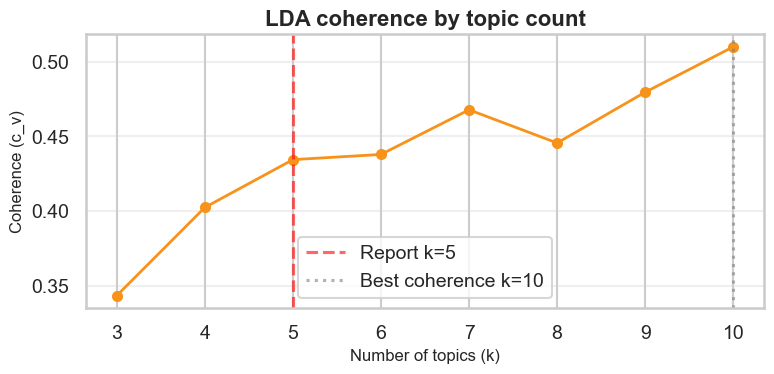

Best coherence k=10; training with k=5
Training LDA k=5 (passes=20)...


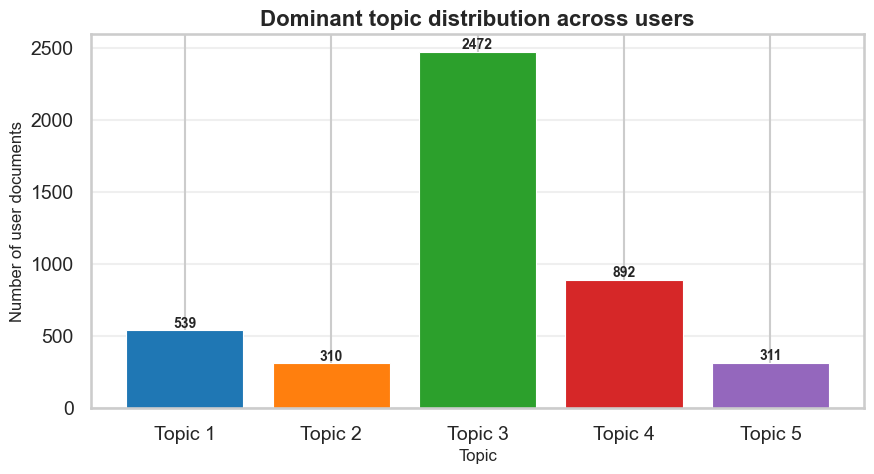

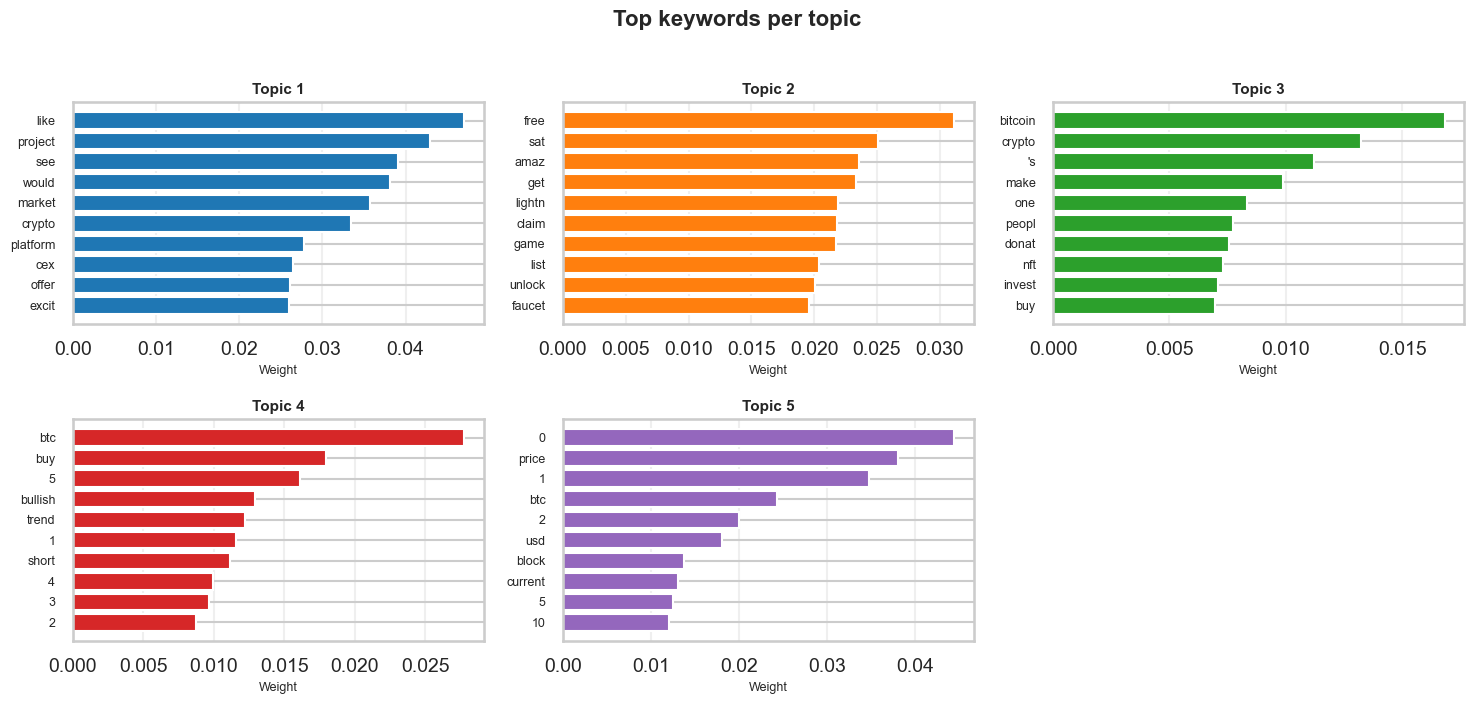

,topic_id,label,top_keywords,users_dominant_count,pct_users_dominant,coherence_cv_at_search
0,1,Market Analysis,"like, project, see, would, market, crypto, pla...",539,11.91,0.43449
1,2,General Bitcoin Discussion,"free, sat, amaz, get, lightn, claim, game, lis...",310,6.85,0.43449
2,3,Investment,"bitcoin, crypto, 's, make, one, peopl, donat, ...",2472,54.64,0.43449
3,4,Buying Signal,"btc, buy, 5, bullish, trend, 1, short, 4, 3, 2",892,19.72,0.43449
4,5,Price / Market Movement,"0, price, 1, btc, 2, usd, block, current, 5, 10",311,6.87,0.43449


Interactive LDAvis (may take a moment)...


In [ ]:
# Topic modeling: latent Dirichlet allocation (LDA) with k=5 topics

# Topic labeling hints
# Map common keywords to human-readable topic labels
LDA_LABEL_HINTS = {
    "price": "Price / Market Movement", "market": "Market Analysis",
    "trade": "Trading & Exchange", "trading": "Trading & Exchange",
    "network": "Bitcoin Network / Tech", "wallet": "Wallets & Security",
    "node": "Node / Infrastructure", "mining": "Mining",
    "bank": "Banking / Finance", "halving": "Halving / Supply",
    "etf": "ETF / Institutional", "bull": "Bullish Sentiment",
    "bear": "Bearish Sentiment", "block": "Blockchain / Tech",
    "regulation": "Regulation / Policy", "invest": "Investment",
    "buy": "Buying Signal", "sell": "Selling Signal",
    "fear": "Fear / FUD", "news": "News & Media",
    "project": "Projects / Altcoin Promotion", "nft": "NFT / Web3",
    "sanction": "Regulation / Geopolitics",
}


def lda_suggest_label(word_weights):
    # Auto-label topic by checking if top keywords match any hints.
    words = [w for w, _ in word_weights]
    for keyword, hint in LDA_LABEL_HINTS.items():
        if keyword in words:
            return hint
    return "General Bitcoin Discussion"


def lda_aggregate_by_user(dataframe):
    # Aggregate tweets by user: concatenate all cleaned texts for LDA documents.
    user_docs = (
        dataframe.groupby("user_name")["text"]
        .apply(lambda texts: " ".join(texts.astype(str)))
        .reset_index()
    )
    user_docs.columns = ["user_name", "document"]
    return user_docs[user_docs["document"].str.strip() != ""].reset_index(drop=True)


def lda_build_corpus(user_docs):
    # Build LDA corpus:
    # 1. Tokenize documents (already space-separated from preprocessing)
    # 2. Build dictionary, filter extremes, create bag-of-words corpus
    tokenised = [doc.split() for doc in user_docs["document"]]
    dictionary = corpora.Dictionary(tokenised)
    # Remove tokens that appear in <2 docs or >90% of docs, keep top 10k terms
    dictionary.filter_extremes(no_below=2, no_above=0.9, keep_n=10_000)
    bow_corpus = [dictionary.doc2bow(doc) for doc in tokenised]
    print(f"Vocabulary: {len(dictionary):,} terms | documents: {len(bow_corpus):,}")
    return tokenised, dictionary, bow_corpus


def lda_coherence_search(tokenised, dictionary, bow_corpus, min_k=3, max_k=10):
    # Search for optimal number of topics using coherence metric (c_v).
    # Trains LDA for k in [min_k, max_k] and plots coherence curve.
    coherence_scores = {}
    print(f"Coherence search k={min_k}..{max_k}")
    for k in range(min_k, max_k + 1):
        model = LdaModel(
            corpus=bow_corpus, id2word=dictionary, num_topics=k,
            random_state=42, passes=10, alpha="auto", per_word_topics=True,
        )
        cm = CoherenceModel(model=model, texts=tokenised, dictionary=dictionary, coherence="c_v")
        coherence_scores[k] = cm.get_coherence()
        print(f"  k={k:2d}  coherence={coherence_scores[k]:.4f}")
    best_k = max(coherence_scores, key=coherence_scores.get)
    # Plot coherence curve
    ks, vals = list(coherence_scores.keys()), list(coherence_scores.values())
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(ks, vals, marker="o", color="#F7931A", linewidth=2, markersize=7)
    ax.axvline(LDA_K, color="red", linestyle="--", alpha=0.6, label=f"Report k={LDA_K}")
    ax.axvline(best_k, color="gray", linestyle=":", alpha=0.6, label=f"Best coherence k={best_k}")
    ax.set_xlabel("Number of topics (k)", fontsize=12)
    ax.set_ylabel("Coherence (c_v)", fontsize=12)
    ax.set_title("LDA coherence by topic count", fontsize=16, fontweight="bold")
    ax.legend()
    ax.set_xticks(ks)
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    plt.show()
    return coherence_scores, best_k


def lda_train(bow_corpus, dictionary, num_topics):
    # Train LDA model with specified number of topics.
    # Uses 20 passes with auto alpha/eta.
    print(f"Training LDA k={num_topics} (passes=20)...")
    model = LdaModel(
        corpus=bow_corpus, id2word=dictionary, num_topics=num_topics,
        random_state=42, passes=20, alpha="auto", eta="auto", per_word_topics=True,
    )
    return model


def lda_dominant_counts(model, bow_corpus, num_topics):
    # For each document, find dominant topic and count across all users.
    counts = [0] * num_topics
    for bow in bow_corpus:
        if not bow:
            continue
        topic_dist = model.get_document_topics(bow)
        dominant = max(topic_dist, key=lambda x: x[1])
        counts[dominant[0]] += 1
    total = sum(counts) or 1
    return counts, [100.0 * c / total for c in counts]


# Prepare data for LDA
# Keep only tweets with non-empty cleaned text
lda_df = df.dropna(subset=["text"])
lda_df = lda_df[lda_df["text"].astype(str).str.strip() != ""].reset_index(drop=True)
print(f"Usable tweets for LDA: {len(lda_df):,}")

# Build corpus
user_docs_lda = lda_aggregate_by_user(lda_df)
print(f"User documents: {len(user_docs_lda):,}")
tokenised, dictionary, bow_corpus = lda_build_corpus(user_docs_lda)

# Coherence search
coherence_scores, best_k_coherence = lda_coherence_search(tokenised, dictionary, bow_corpus)
print(f"Best coherence k={best_k_coherence}; training with k={LDA_K}")

# Train LDA model
lda_model = lda_train(bow_corpus, dictionary, LDA_K)
topic_counts, pcts = lda_dominant_counts(lda_model, bow_corpus, LDA_K)

# Plot 1: Dominant topic distribution
labels = [f"Topic {i+1}" for i in range(LDA_K)]
colors = list(mcolors.TABLEAU_COLORS.values())[:LDA_K]
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(labels, topic_counts, color=colors, edgecolor="white", linewidth=0.8)
for bar, count in zip(bars, topic_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3, str(count),
            ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set_xlabel("Topic", fontsize=12)
ax.set_ylabel("Number of user documents", fontsize=12)
ax.set_title("Dominant topic distribution across users", fontsize=16, fontweight="bold")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

# Plot 2: Top keywords per topic
# Show 10 most relevant terms for each topic
cols = min(LDA_K, 3)
rows_n = (LDA_K + cols - 1) // cols
fig, axes = plt.subplots(rows_n, cols, figsize=(cols * 5, rows_n * 3.5))
axes_flat = np.atleast_1d(axes).flatten()
for i in range(LDA_K):
    ax = axes_flat[i]
    words = lda_model.show_topic(i, topn=10)
    terms = [w for w, _ in reversed(words)]
    wts = [v for _, v in reversed(words)]
    ax.barh(terms, wts, color=colors[i % len(colors)], edgecolor="white")
    ax.set_title(f"Topic {i+1}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Weight", fontsize=9)
    ax.tick_params(axis="y", labelsize=9)
    ax.grid(axis="x", alpha=0.3)
# Hide unused subplots
for j in range(LDA_K, len(axes_flat)):
    axes_flat[j].set_visible(False)
fig.suptitle("Top keywords per topic", fontsize=16, fontweight="bold", y=1.01)
fig.tight_layout()
plt.show()

# Build summary table
# For each topic: id, auto-generated label, top keywords, and distribution info
topics_rows = []
for topic_id, word_weights in lda_model.show_topics(num_topics=-1, num_words=10, formatted=False):
    topics_rows.append({
        "topic_id": topic_id + 1,
        "label": lda_suggest_label(word_weights),
        "top_keywords": ", ".join(w for w, _ in word_weights),
        "users_dominant_count": topic_counts[topic_id],
        "pct_users_dominant": round(pcts[topic_id], 2),
        "coherence_cv_at_search": coherence_scores.get(LDA_K, np.nan),
    })
topics_table = pd.DataFrame(topics_rows)
display(topics_table)

# Interactive visualization: pyLDAvis
# Generate interactive 2D visualization of topics and their relationships
print("Interactive LDAvis (may take a moment)...")
pyLDAvis.enable_notebook()
lda_vis = pyLDAvis.gensim_models.prepare(lda_model, bow_corpus, dictionary, sort_topics=False, mds="mmds")
pyLDAvis.display(lda_vis)
